# 02 – Distributions and Outliers

In this notebook we look at how the target and the main features are distributed, check for outliers or suspicious extreme values, and decide what to do with them. We also check the categorical and binary features for imbalances or redundancies.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Consistent visual style
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

PERIOD_MAP = {"201803": "Q1 2018", "201806": "Q2 2018", "201809": "Q3 2018", "201812": "Q4 2018"}

df = pd.read_parquet("../data/processed/listings_01.parquet")

print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded: 75,795 rows × 39 columns


In [2]:
main_num_cols = ["PRICE", "CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER",
                 "FLOORCLEAN", "CADCONSTRUCTIONYEAR", "CADMAXBUILDINGFLOOR",
                 "CADDWELLINGCOUNT", "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]

df[main_num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
PRICE,75795.0,389080.183389,412459.348500,21000.000000,157000.000000,257000.000000,457000.000000,8.133000e+06
CONSTRUCTEDAREA,75795.0,100.255386,66.470333,21.000000,62.000000,82.000000,115.000000,9.850000e+02
ROOMNUMBER,75795.0,2.569272,1.198722,0.000000,2.000000,3.000000,3.000000,2.000000e+01
BATHNUMBER,75795.0,1.570816,0.836367,0.000000,1.000000,1.000000,2.000000,2.000000e+01
FLOORCLEAN,75795.0,2.714467,2.211543,-1.000000,1.000000,2.000000,4.000000,1.100000e+01
CADCONSTRUCTIONYEAR,75795.0,1965.465400,28.920675,1623.000000,1955.000000,1967.000000,1983.000000,2.018000e+03
CADMAXBUILDINGFLOOR,75795.0,6.360868,2.842924,0.000000,5.000000,6.000000,8.000000,2.600000e+01
CADDWELLINGCOUNT,75795.0,38.714387,53.303842,1.000000,12.000000,21.000000,39.000000,1.499000e+03
DISTANCE_TO_CITY_CENTER,75795.0,4.476765,2.671411,0.015374,2.403508,4.114314,6.219253,1.415881e+01
DISTANCE_TO_METRO,75795.0,0.470128,0.595199,0.001416,0.212755,0.330032,0.519243,9.344541e+00


## 1. Target variable: PRICE

We start by looking at the distribution of the price, since that's what we're trying to predict.

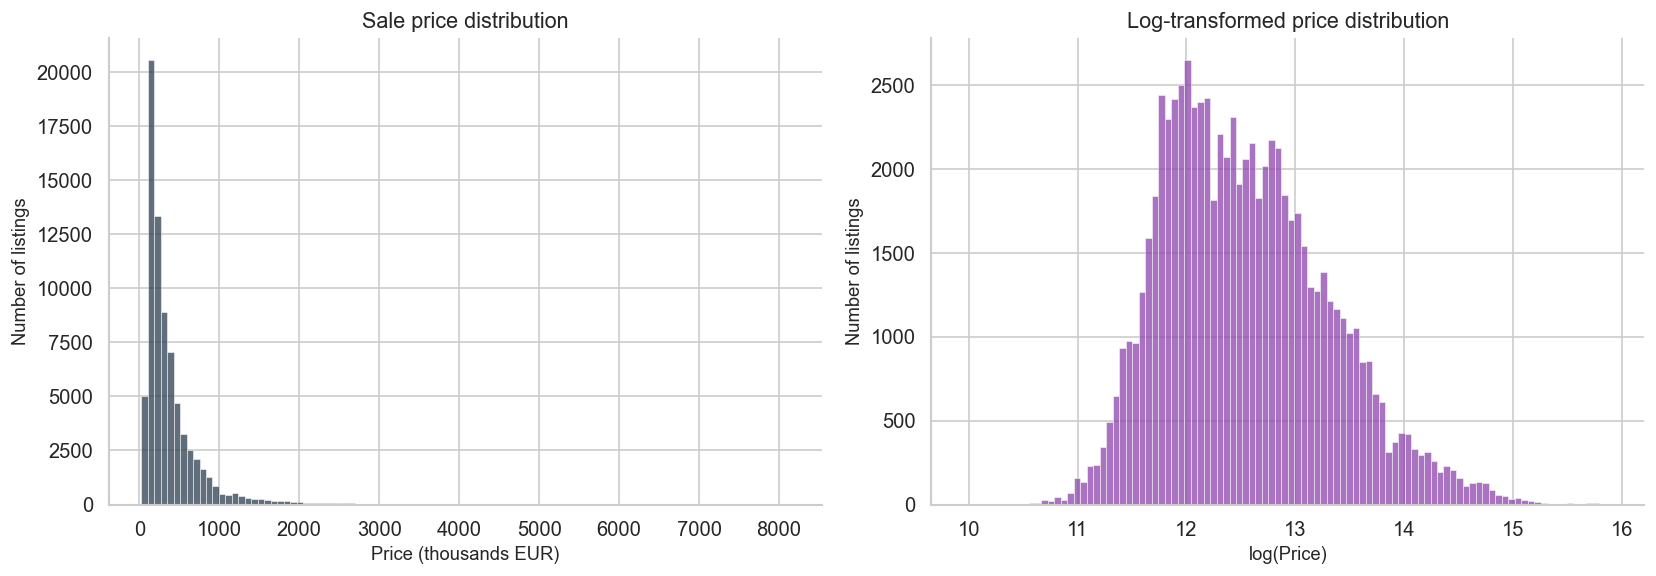

Skewness PRICE:      4.07
Skewness log(PRICE): 0.54


In [3]:
price = df["PRICE"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(price / 1000, bins=100, ax=axes[0], color="#2c3e50", edgecolor="white", linewidth=0.3)
axes[0].set_xlabel("Price (thousands EUR)")
axes[0].set_ylabel("Number of listings")
axes[0].set_title("Sale price distribution")

sns.histplot(np.log(price), bins=100, ax=axes[1], color="#8e44ad", edgecolor="white", linewidth=0.3)
axes[1].set_xlabel("log(Price)")
axes[1].set_ylabel("Number of listings")
axes[1].set_title("Log-transformed price distribution")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Skewness PRICE:      {price.skew():.2f}")
print(f"Skewness log(PRICE): {np.log(price).skew():.2f}")

The raw price is heavily right-skewed — most flats are under 500k but a few go up to several million. After applying a log transformation the distribution looks much more symmetric. This tells us that the model should predict log(PRICE) rather than PRICE directly, and that we should evaluate outliers on the log scale too.

In [4]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

low, high = iqr_bounds(price)
n_out = ((price < low) | (price > high)).sum()
print(f"IQR on PRICE:      [{low:,.0f}, {high:,.0f}] EUR  -> {n_out:,} outliers ({n_out/len(price):.1%})")

log_price = np.log(price)
log_low, log_high = iqr_bounds(log_price)
n_out_log = ((log_price < log_low) | (log_price > log_high)).sum()
print(f"IQR on log(PRICE): [{np.exp(log_low):,.0f}, {np.exp(log_high):,.0f}] EUR  -> {n_out_log:,} outliers ({n_out_log/len(price):.1%})")

IQR on PRICE:      [-293,000, 907,000] EUR  -> 5,494 outliers (7.2%)
IQR on log(PRICE): [31,614, 2,269,557] EUR  -> 679 outliers (0.9%)


Extreme-outlier fence (3·IQR on log scale): [6,366, 11,271,088] EUR
Listings outside the fence: 0

Price per m² in the original file: 805 – 9,998 EUR/m²
Price per m² after notebook 01:    805 – 9,998 EUR/m²


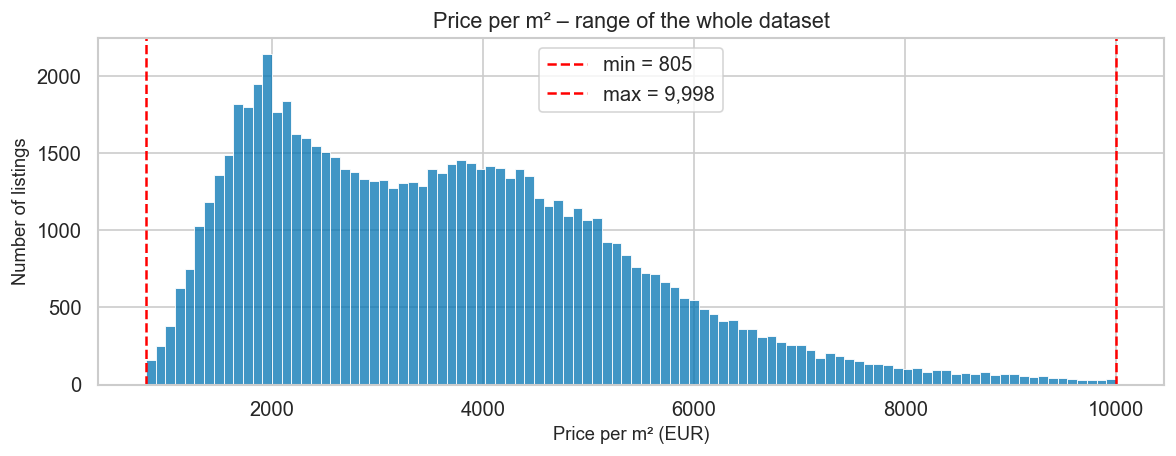

In [5]:
log_low3, log_high3 = iqr_bounds(log_price, k=3)
print(f"Extreme-outlier fence (3·IQR on log scale): [{np.exp(log_low3):,.0f}, {np.exp(log_high3):,.0f}] EUR")
print(f"Listings outside the fence: {((log_price < log_low3) | (log_price > log_high3)).sum()}")

price_m2 = df["PRICE"] / df["CONSTRUCTEDAREA"]
raw = pd.read_csv("../data/Madrid_Sale.csv", usecols=["UNITPRICE"])
print(f"\nPrice per m² in the original file: {raw['UNITPRICE'].min():,.0f} – {raw['UNITPRICE'].max():,.0f} EUR/m²")
print(f"Price per m² after notebook 01:    {price_m2.min():,.0f} – {price_m2.max():,.0f} EUR/m²")

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(price_m2, bins=100, ax=ax)
ax.axvline(price_m2.min(), color="red", linestyle="--", label=f"min = {price_m2.min():,.0f}")
ax.axvline(price_m2.max(), color="red", linestyle="--", label=f"max = {price_m2.max():,.0f}")
ax.set_xlabel("Price per m² (EUR)")
ax.set_ylabel("Number of listings")
ax.set_title("Price per m² – range of the whole dataset")
ax.legend()
plt.tight_layout()
plt.show()

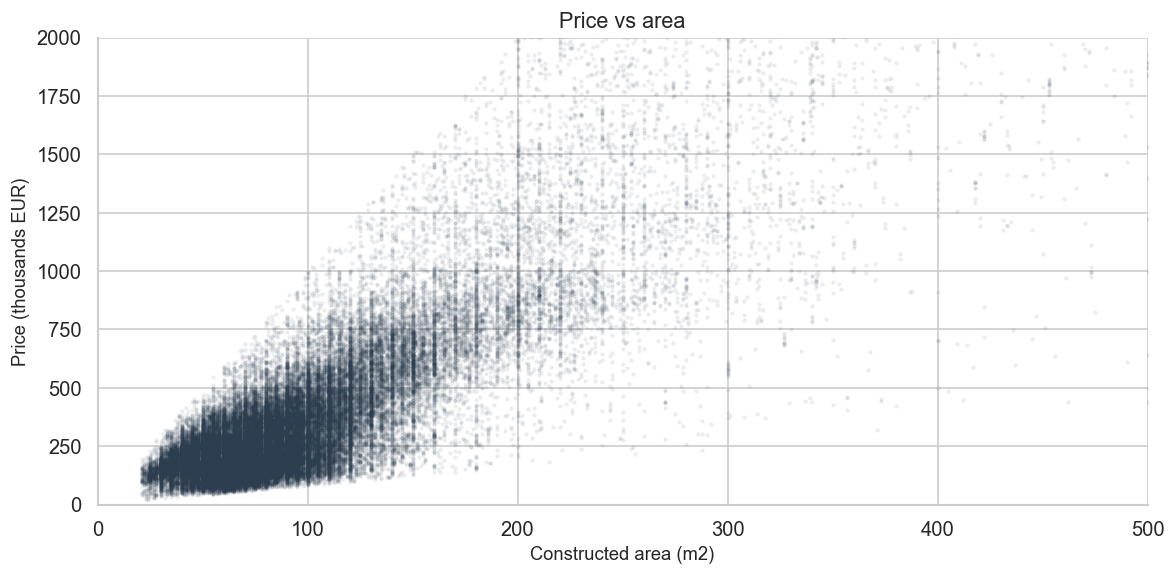

In [6]:
subset = df[df["CONSTRUCTEDAREA"] <= 500]

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(subset["CONSTRUCTEDAREA"], subset["PRICE"] / 1000,
           alpha=0.06, s=3, color="#2c3e50")
ax.set_xlim(0, 500)
ax.set_ylim(0, 2000)
ax.set_xlabel("Constructed area (m2)")
ax.set_ylabel("Price (thousands EUR)")
ax.set_title("Price vs area")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Decision on price outliers

Using the standard 1.5 IQR rule on the raw price flags 7.2% of listings and gives a negative lower bound, which doesn't make sense. On the log scale the same rule flags only 679 listings (0.9%), and the extreme-outlier fence (3 IQR) catches zero listings — so there are no truly extreme prices.

It also turns out the dataset was pre-filtered by its authors: the price per m2 ranges from 805 to 9,998 EUR/m2 with a sharp cutoff at both ends, meaning listings with implausible unit prices were already removed before publication.

Looking at the scatter of price vs area, the most expensive listings are also the largest ones — they are real luxury properties, not errors. So we keep everything as is and don't remove any price outliers.

## 2. Main numerical features

Let's check the distributions and look for any extreme values that might be errors.

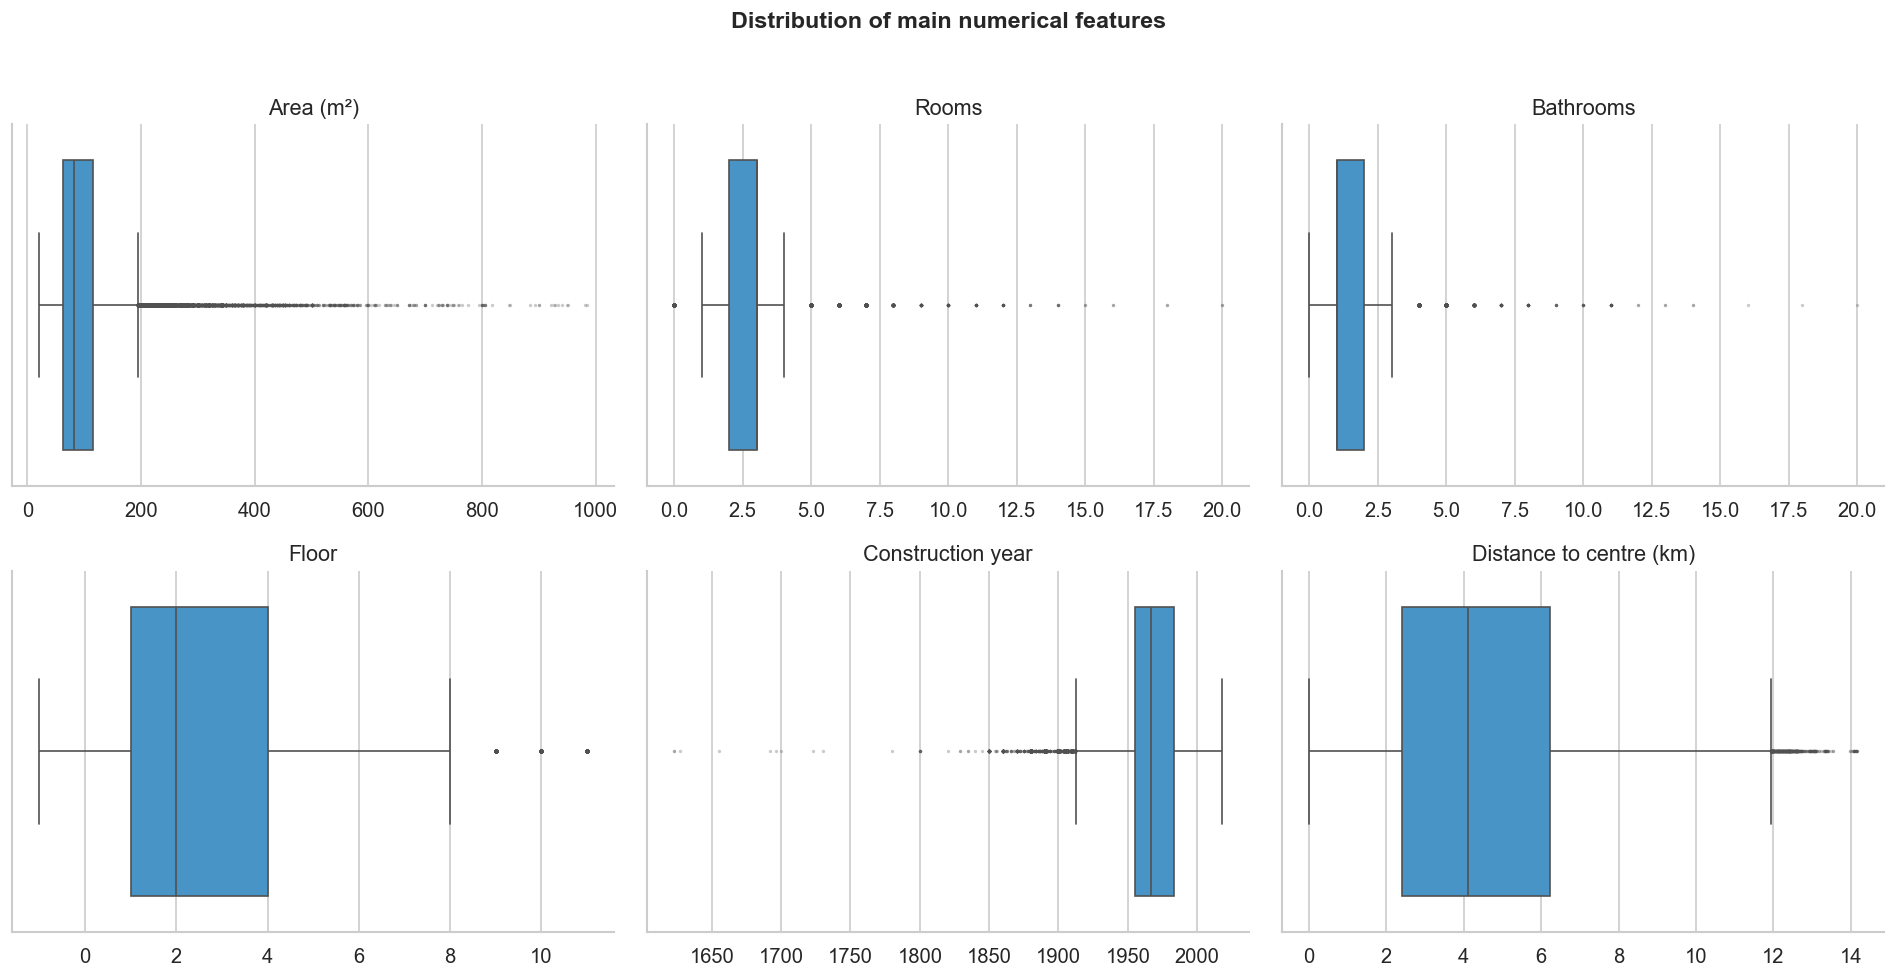

In [7]:
feat_cols = ["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "FLOORCLEAN",
             "CADCONSTRUCTIONYEAR", "DISTANCE_TO_CITY_CENTER"]

readable_names = {
    "CONSTRUCTEDAREA": "Area (m²)",
    "ROOMNUMBER": "Rooms",
    "BATHNUMBER": "Bathrooms",
    "FLOORCLEAN": "Floor",
    "CADCONSTRUCTIONYEAR": "Construction year",
    "DISTANCE_TO_CITY_CENTER": "Distance to centre (km)"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), feat_cols):
    sns.boxplot(x=df[col], ax=ax, color="#3498db", flierprops=dict(marker=".", markersize=2, alpha=0.3))
    ax.set_title(readable_names.get(col, col))
    ax.set_xlabel("")
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Distribution of main numerical features", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

Before applying any outlier treatment, we look at the actual listings that would be affected to make sure we're not throwing away real data.

In [8]:
large = df[df["CONSTRUCTEDAREA"] > 500]
print(f"Listings with CONSTRUCTEDAREA > 500 m2: {len(large)}")
print(large[["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "PRICE", "DISTANCE_TO_CITY_CENTER"]].describe())

Listings with CONSTRUCTEDAREA > 500 m2: 189
       CONSTRUCTEDAREA  ROOMNUMBER  BATHNUMBER         PRICE  \
count       189.000000  189.000000  189.000000  1.890000e+02   
mean        636.417989    5.925926    4.708995  3.254786e+06   
std         119.578826    3.199869    2.640715  1.545367e+06   
min         501.000000    0.000000    1.000000  4.880000e+05   
25%         548.000000    5.000000    3.000000  2.349000e+06   
50%         580.000000    6.000000    4.000000  3.039000e+06   
75%         720.000000    7.000000    6.000000  4.024000e+06   
max         985.000000   20.000000   20.000000  8.133000e+06   

       DISTANCE_TO_CITY_CENTER  
count               189.000000  
mean                  3.017960  
std                   2.003907  
min                   0.083329  
25%                   1.710670  
50%                   2.489297  
75%                   3.908721  
max                  10.908814  


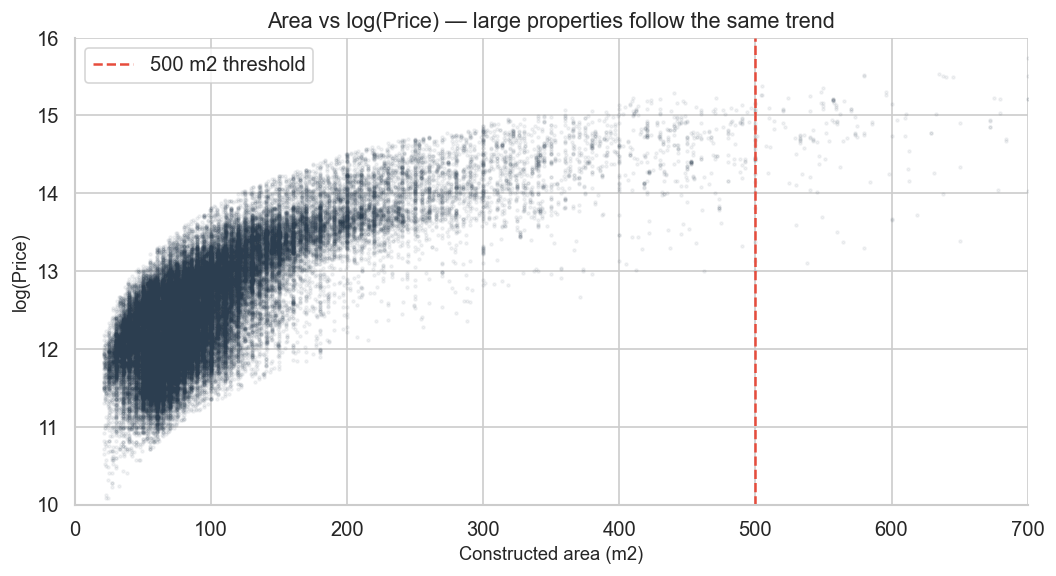

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df["CONSTRUCTEDAREA"], np.log(df["PRICE"]),
           alpha=0.06, s=3, color="#2c3e50")
ax.axvline(500, color="#e74c3c", linestyle="--", lw=1.5, label="500 m2 threshold")
ax.set_xlim(0, 700)
ax.set_ylim(10, 16)
ax.set_xlabel("Constructed area (m2)")
ax.set_ylabel("log(Price)")
ax.set_title("Area vs log(Price) — large properties follow the same trend")
ax.legend(frameon=True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

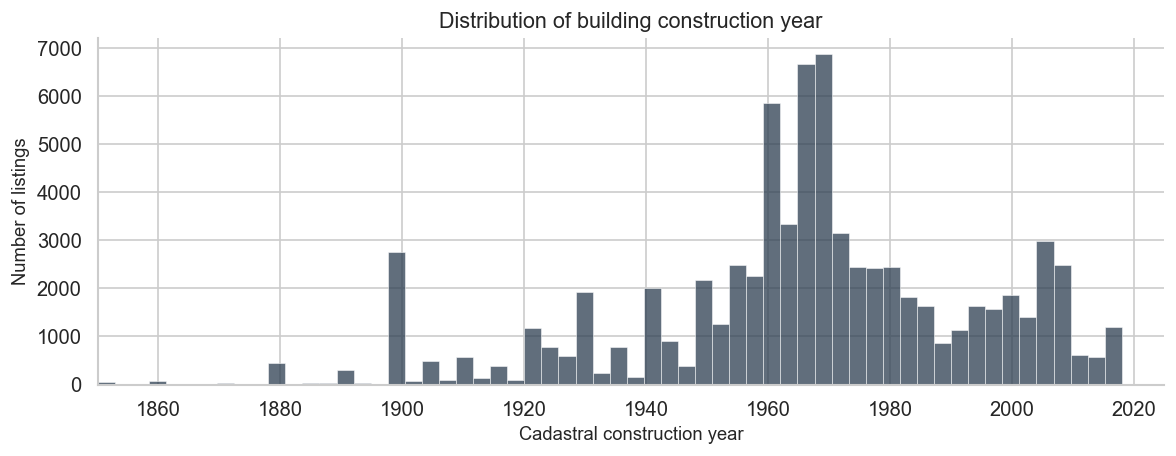

Buildings before 1900: 1095 (1.4%)
Median price (pre-1900): 358,000 EUR
Median price (1900+):    255,000 EUR


In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df["CADCONSTRUCTIONYEAR"][df["CADCONSTRUCTIONYEAR"] >= 1850],
             bins=60, ax=ax, color="#2c3e50", edgecolor="white", linewidth=0.3)
ax.set_xlim(1850, 2025)
ax.set_xlabel("Cadastral construction year")
ax.set_ylabel("Number of listings")
ax.set_title("Distribution of building construction year")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

old = df[df["CADCONSTRUCTIONYEAR"] < 1900]
print(f"Buildings before 1900: {len(old)} ({len(old)/len(df):.1%})")
print(f"Median price (pre-1900): {old['PRICE'].median():,.0f} EUR")
print(f"Median price (1900+):    {df[df['CADCONSTRUCTIONYEAR'] >= 1900]['PRICE'].median():,.0f} EUR")

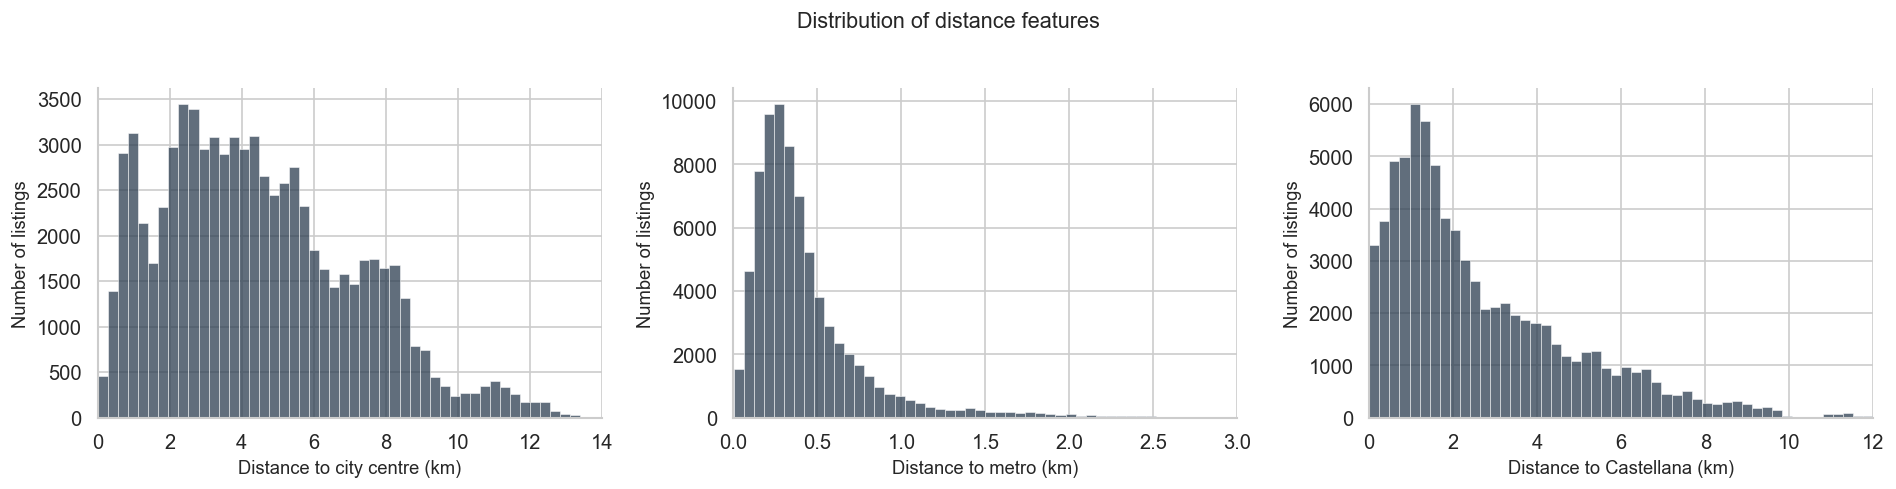

CADDWELLINGCOUNT > 500: 78 listings
       CADDWELLINGCOUNT  CADMAXBUILDINGFLOOR         PRICE
count         78.000000            78.000000  7.800000e+01
mean         607.474359             9.653846  5.946346e+05
std          130.127482             2.931366  2.104917e+05
min          501.000000             5.000000  7.500000e+04
25%          532.000000             8.000000  4.620000e+05
50%          574.000000             9.000000  5.640000e+05
75%          685.250000            14.000000  7.227500e+05
max         1499.000000            14.000000  1.372000e+06


In [11]:
dist_cols = ["DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO", "DISTANCE_TO_CASTELLANA"]
dist_labels = ["Distance to city centre (km)", "Distance to metro (km)", "Distance to Castellana (km)"]
dist_xlims = [(0, 14), (0, 3), (0, 12)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, label, xlim in zip(axes, dist_cols, dist_labels, dist_xlims):
    subset = df[df[col] <= xlim[1]]
    sns.histplot(subset[col], bins=50, ax=ax, color="#2c3e50", edgecolor="white", linewidth=0.3)
    ax.set_xlim(xlim)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of listings")
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Distribution of distance features", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"CADDWELLINGCOUNT > 500: {(df['CADDWELLINGCOUNT'] > 500).sum()} listings")
print(df[df["CADDWELLINGCOUNT"] > 500][["CADDWELLINGCOUNT", "CADMAXBUILDINGFLOOR", "PRICE"]].describe())

### Decisions on feature outliers

We checked each group of extreme values individually:

The 189 listings with more than 500 m2 are legitimate — their price scales proportionally with their area. The 1,095 buildings from before 1900 are historic properties that actually have a higher median price than newer ones (358k vs 255k EUR), so they carry useful information. The distance features have smooth distributions with nothing suspicious. And the 78 listings with more than 500 dwellings in their building are just large residential complexes with consistent data.

In the end, we don't remove or cap anything here. All the extreme values we inspected are consistent with each other (big area, many rooms, high price) and represent real properties in the market.

## 3. Categorical features

We check how the listings are distributed across the different categories.

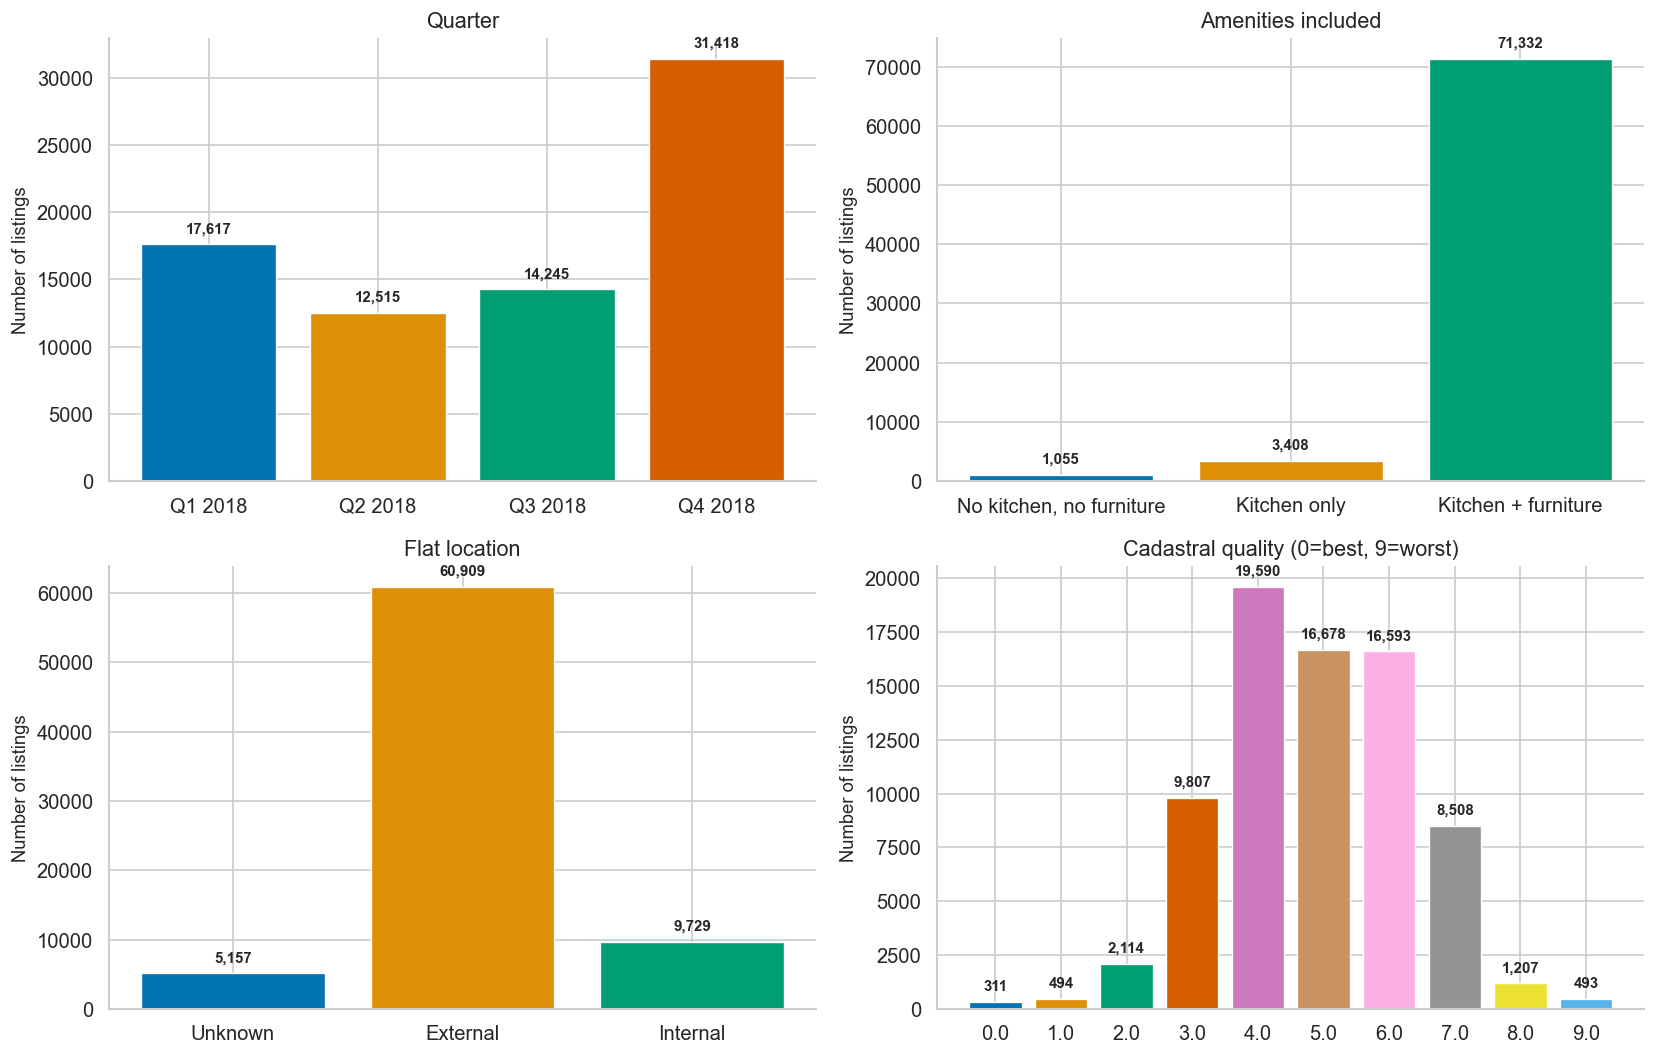


PERIOD:
PERIOD
201803    0.232
201806    0.165
201809    0.188
201812    0.415
Name: proportion, dtype: float64

AMENITYID:
AMENITYID
1    0.014
2    0.045
3    0.941
Name: proportion, dtype: float64

FLATLOCATIONID:
FLATLOCATIONID
0    0.068
1    0.804
2    0.128
Name: proportion, dtype: float64

CADASTRALQUALITYID:
CADASTRALQUALITYID
0.0    0.004
1.0    0.007
2.0    0.028
3.0    0.129
4.0    0.258
5.0    0.220
6.0    0.219
7.0    0.112
8.0    0.016
9.0    0.007
Name: proportion, dtype: float64


In [12]:
cat_cols = ["PERIOD", "AMENITYID", "FLATLOCATIONID", "CADASTRALQUALITYID"]

cat_labels = {
    "PERIOD": "Quarter",
    "AMENITYID": "Amenities included",
    "FLATLOCATIONID": "Flat location",
    "CADASTRALQUALITYID": "Cadastral quality (0=best, 9=worst)"
}

# Human-readable tick labels (from the official idealista18 documentation)
tick_maps = {
    "PERIOD": PERIOD_MAP,
    "FLATLOCATIONID": {0: "Unknown", 1: "External", 2: "Internal"},
    "AMENITYID": {1: "No kitchen, no furniture", 2: "Kitchen only", 3: "Kitchen + furniture"},
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
palette = sns.color_palette("colorblind")

for ax, col in zip(axes.ravel(), cat_cols):
    counts = df[col].value_counts().sort_index()
    tick_map = tick_maps.get(col, {})
    labels = [tick_map.get(v, str(v)) for v in counts.index]

    bars = ax.bar(labels, counts.values, color=palette[:len(counts)], edgecolor="white", linewidth=0.8)
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + counts.max() * 0.02,
                f"{val:,}", ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_title(cat_labels.get(col, col))
    ax.set_ylabel("Number of listings")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(normalize=True).sort_index().round(3))

In [13]:
quality_price = df.groupby("CADASTRALQUALITYID")["PRICE"].agg(["count", "median"])
quality_price["median"] = quality_price["median"].round(0)
quality_price

,count,median
CADASTRALQUALITYID,,
0.0,311,859000.0
1.0,494,1061000.0
2.0,2114,747000.0
3.0,9807,504000.0
4.0,19590,354000.0
5.0,16678,265000.0
6.0,16593,160000.0
7.0,8508,138000.0
8.0,1207,175000.0


PERIOD is not balanced — Q4 has 41.5% of the listings while the other quarters range from 16.5% to 23.2%. This was already noted in notebook 00 and might be a data collection issue. We keep it as a feature so the model can account for any time effect.

AMENITYID is very unbalanced: 94% of listings are level 3 (kitchen + furniture). This means the variable probably won't add much predictive power, but we keep it for now.

FLATLOCATIONID has three categories after our imputation in notebook 01: 80% external, 13% internal, 7% unknown.

CADASTRALQUALITYID goes from 0 to 9. The median price drops from about 1 million EUR at level 1 down to 138k at level 7, which confirms that lower levels mean higher quality. Levels 0, 8 and 9 have few listings so their medians are less reliable.

All values are valid — nothing to fix here.

## 4. Binary features

We check how common each binary feature is and look for redundancies.

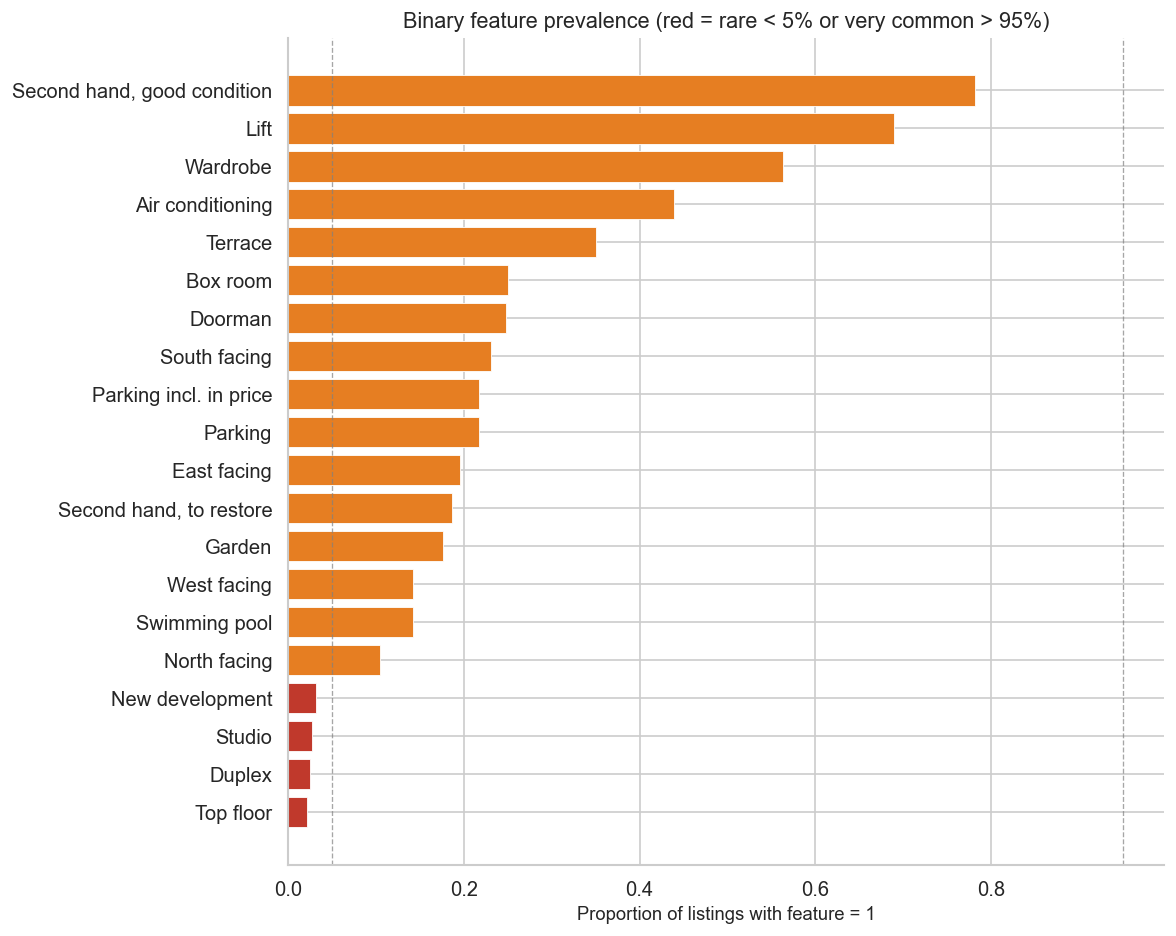

Rare features (< 5%):
ISINTOPFLOOR     0.022
ISDUPLEX         0.025
ISSTUDIO         0.027
BUILTTYPEID_1    0.032
dtype: float64

Very common features (> 95%):
Series([], dtype: float64)


In [14]:
binary_cols = [c for c in df.columns if c.startswith("HAS") or c.startswith("IS") or c.startswith("BUILTTYPEID")]

proportions = df[binary_cols].mean().sort_values(ascending=True)

# Readable names
readable = {
    "HASTERRACE": "Terrace", "HASLIFT": "Lift", "HASAIRCONDITIONING": "Air conditioning",
    "HASPARKINGSPACE": "Parking", "ISPARKINGSPACEINCLUDEDINPRICE": "Parking incl. in price",
    "HASNORTHORIENTATION": "North facing", "HASSOUTHORIENTATION": "South facing",
    "HASEASTORIENTATION": "East facing", "HASWESTORIENTATION": "West facing",
    "HASBOXROOM": "Box room", "HASWARDROBE": "Wardrobe", "HASSWIMMINGPOOL": "Swimming pool",
    "HASDOORMAN": "Doorman", "HASGARDEN": "Garden", "ISDUPLEX": "Duplex",
    "ISSTUDIO": "Studio", "ISINTOPFLOOR": "Top floor",
    "BUILTTYPEID_1": "New development", "BUILTTYPEID_2": "Second hand, to restore", "BUILTTYPEID_3": "Second hand, good condition",
    }
labels = [readable.get(c, c) for c in proportions.index]

fig, ax = plt.subplots(figsize=(10, 8))
colors = ["#e67e22" if 0.05 < v < 0.95 else "#c0392c" for v in proportions]
ax.barh(labels, proportions.values, color=colors, edgecolor="white", linewidth=0.5)
ax.set_xlabel("Proportion of listings with feature = 1")
ax.set_title("Binary feature prevalence (red = rare < 5% or very common > 95%)")
ax.axvline(0.05, color="gray", linestyle="--", lw=0.8, alpha=0.7)
ax.axvline(0.95, color="gray", linestyle="--", lw=0.8, alpha=0.7)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print("Rare features (< 5%):")
print(proportions[proportions < 0.05].round(3))
print("\nVery common features (> 95%):")
print(proportions[proportions > 0.95].round(3))

In [15]:
same = (df["HASPARKINGSPACE"] == df["ISPARKINGSPACEINCLUDEDINPRICE"]).mean()
print(f"HASPARKINGSPACE == ISPARKINGSPACEINCLUDEDINPRICE in {same:.1%} of listings")

built_cols = ["BUILTTYPEID_1", "BUILTTYPEID_2", "BUILTTYPEID_3"]
print(f"\nNumber of BUILTTYPEID flags per listing: {df[built_cols].sum(axis=1).value_counts().to_dict()}")

orient_cols = ["HASNORTHORIENTATION", "HASSOUTHORIENTATION", "HASEASTORIENTATION", "HASWESTORIENTATION"]
n_orient = df[orient_cols].sum(axis=1)
print(f"Listings with no orientation reported: {(n_orient == 0).mean():.1%}")
print(f"Listings with 2 or more orientations:  {(n_orient >= 2).mean():.1%}")

HASPARKINGSPACE == ISPARKINGSPACEINCLUDEDINPRICE in 100.0% of listings

Number of BUILTTYPEID flags per listing: {1: 75795}
Listings with no orientation reported: 53.1%
Listings with 2 or more orientations:  17.9%


A few features are rare (top floor 2.2%, duplex 2.5%, studio 2.7%, new development 3.2%), but we keep them because even rare features can be very informative — a studio is a completely different product from a 3-bedroom flat. No feature is almost constant (the most common is "second hand, good condition" at 78%).

We found one redundancy: HASPARKINGSPACE and ISPARKINGSPACEINCLUDEDINPRICE are identical in 100% of listings. We drop the second one.

The three BUILTTYPEID columns are really one categorical variable (property condition) split into dummies — every listing has exactly one of them set to 1. For linear models we'll need to leave one out to avoid collinearity, but that's for the modelling phase.

The orientation columns are not mutually exclusive: 18% of listings report two or more directions, and 53% report none. So a 0 often means "not reported" rather than "doesn't face that direction".

## Conclusion

This notebook turned out to be less dramatic than expected — unlike a typical scraped dataset, this one had already been cleaned by its authors (the price per m2 is capped between 805 and 9,998 EUR), so there were no absurd values to deal with.

The main finding is that PRICE needs a log transformation. The raw distribution is very skewed (skewness 4.07), but log(PRICE) is close to symmetric (skewness 0.54). This will be our modelling target.

We checked all the numerical features for outliers — large areas, old buildings, distant properties, big complexes — and in every case the extreme values turned out to be real. They are consistent with each other (a 900 m2 flat also has 8 bathrooms and costs 7 million EUR), so removing or capping them would throw away legitimate data points.

On the categorical side, PERIOD is unbalanced (Q4 has 41.5% of listings) and AMENITYID is almost constant (94% at level 3). Both are noted for the modelling phase. CADASTRALQUALITYID has a clear monotonic relationship with price, which is promising.

The only action we took was dropping ISPARKINGSPACEINCLUDEDINPRICE since it's identical to HASPARKINGSPACE in every single listing.

We save the result as listings_02.parquet with 75,795 rows and 38 columns for the bivariate analysis in notebook 03.

In [16]:
df = df.drop(columns=["ISPARKINGSPACEINCLUDEDINPRICE"])
print(f"Dropped ISPARKINGSPACEINCLUDEDINPRICE (identical to HASPARKINGSPACE). Shape: {df.shape}")

Dropped ISPARKINGSPACEINCLUDEDINPRICE (identical to HASPARKINGSPACE). Shape: (75795, 38)


In [17]:
df.to_parquet("../data/processed/listings_02.parquet", index=False)
print(f"Saved: {df.shape[0]} rows × {df.shape[1]} columns")

Saved: 75795 rows × 38 columns
